In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("TensorFlow:", tf.__version__)

# Dataset path
dataset_path = Path("../dataset/chest_xray")

# Image and training settings
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

print("Dataset:", dataset_path.resolve())
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

TensorFlow: 2.21.0
Dataset: D:\Tanu H\TanushrisSPace\Projects\DL MINI PROJECT\dataset\chest_xray
Image size: (224, 224)
Batch size: 32


In [2]:
# Load the datasets from folders

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path / "train",
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path / "val",
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path / "test",
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("\nClass names:", train_ds.class_names)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.

Class names: ['NORMAL', 'PNEUMONIA']


In [3]:
# Normalize pixel values from [0, 255] to [0, 1]
normalization_layer = tf.keras.layers.Rescaling(1./255)

# Data augmentation for training images
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
], name="data_augmentation")

print("✅ Normalization and augmentation layers created.")

✅ Normalization and augmentation layers created.


In [4]:
# Improve input pipeline performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("✅ Dataset pipeline optimized with prefetching.")

✅ Dataset pipeline optimized with prefetching.


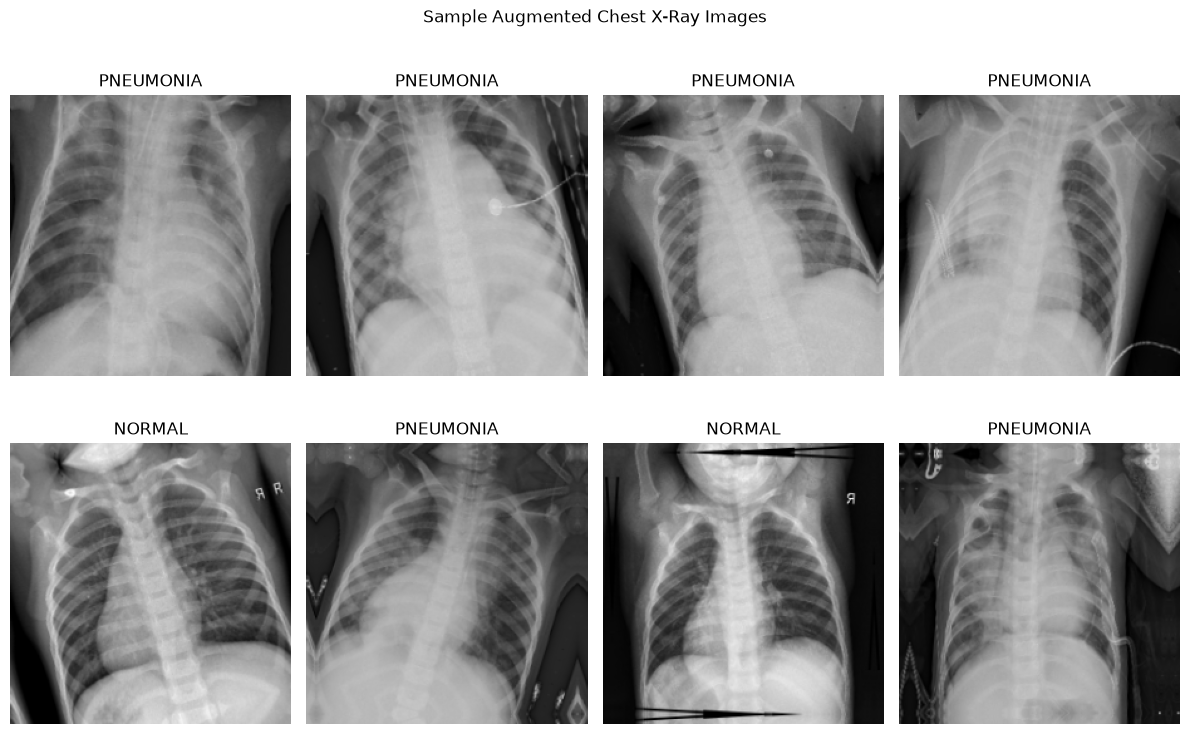

In [5]:
# Visualize augmented training images

plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    # Apply augmentation only for visualization
    augmented_images = data_augmentation(images)

    for i in range(8):
        ax = plt.subplot(2, 4, i + 1)

        # Convert pixel values back to [0, 1] for display
        image = augmented_images[i].numpy() / 255.0

        plt.imshow(image)
        plt.title(
            "PNEUMONIA" if labels[i].numpy()[0] == 1 else "NORMAL"
        )
        plt.axis("off")

plt.suptitle("Sample Augmented Chest X-Ray Images")
plt.tight_layout()
plt.show()